In [10]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import os 

In [23]:
!pip install huggingface_hub pandas pyarrow

In [24]:
!pip install boto3

In [25]:
# Install: pip install boto3
from huggingface_hub import download_bucket_files, sync_bucket
import pandas as pd
import os

# 1. Download specific data files from your bucket locally
download_bucket_files(
    bucket_id="vinayk2005/ai-text-detection-pile-bucket",
    files=[
        ("data/train.csv", "./data/train.csv")  # Replace with exact file name inside data/
    ]
)

# 2. Or sync the entire data folder locally
sync_bucket("hf://buckets/vinayk2005/ai-text-detection-pile-bucket/data", "./local_data")


c:\Users\vinay kumar\anaconda3\Lib\site-packages\huggingface_hub\hf_api.py:15020: UserWarning: File 'data/train.csv' not found in bucket 'vinayk2005/ai-text-detection-pile-bucket'. Skipping.
  warnings.warn(f"File '{path}' not found in bucket '{bucket_id}'. Skipping.")


Sync plan: hf://buckets/vinayk2005/ai-text-detection-pile-bucket/data -> ./local_data
  Uploads: 0
  Downloads: 0
  Deletes: 0
  Skips: 7
Nothing to sync.


SyncPlan(source='hf://buckets/vinayk2005/ai-text-detection-pile-bucket/data', dest='./local_data', timestamp='2026-10-04T13:33:08.622349+00:00', operations=[SyncOperation(action='skip', path='train-00000-of-00007-bc5952582e004d67.parquet', size=757597833, reason='identical', local_mtime='2026-10-04T13:00:27.622411+00:00', remote_mtime='1970-01-01T00:00:00+00:00', bucket_file=None), SyncOperation(action='skip', path='train-00001-of-00007-71c80017bc45f30d.parquet', size=317633760, reason='identical', local_mtime='2026-10-04T13:00:21.323361+00:00', remote_mtime='1970-01-01T00:00:00+00:00', bucket_file=None), SyncOperation(action='skip', path='train-00002-of-00007-ee2d43f396e78fbc.parquet', size=124574604, reason='identical', local_mtime='2026-10-04T13:00:08.940466+00:00', remote_mtime='1970-01-01T00:00:00+00:00', bucket_file=None), SyncOperation(action='skip', path='train-00003-of-00007-529931154b42b51d.parquet', size=137433618, reason='identical', local_mtime='2026-10-04T13:00:08.371645+

In [26]:
import os
print(os.listdir("./local_data"))

['train-00000-of-00007-bc5952582e004d67.parquet', 'train-00001-of-00007-71c80017bc45f30d.parquet', 'train-00002-of-00007-ee2d43f396e78fbc.parquet', 'train-00003-of-00007-529931154b42b51d.parquet', 'train-00004-of-00007-b269dc49374a2c0b.parquet', 'train-00005-of-00007-3dce5e05ddbad789.parquet', 'train-00006-of-00007-3d8a471ba0cf1c8d.parquet']


In [27]:
download_bucket_files(
    bucket_id="vinayk2005/ai-text-detection-pile-bucket",
    files=[
        ("train.csv", "./data/train.csv")  # Adjust exact remote source path if not inside 'data/'
    ]
)

c:\Users\vinay kumar\anaconda3\Lib\site-packages\huggingface_hub\hf_api.py:15020: UserWarning: File 'train.csv' not found in bucket 'vinayk2005/ai-text-detection-pile-bucket'. Skipping.
  warnings.warn(f"File '{path}' not found in bucket '{bucket_id}'. Skipping.")


In [28]:
import os
from huggingface_hub import sync_bucket

# Download bucket contents locally into a folder
sync_bucket("hf://buckets/vinayk2005/ai-text-detection-pile-bucket/data", "./local_data")

# Print all downloaded files and folders
for root, dirs, files in os.walk("./local_data"):
    for file in files:
        print(os.path.join(root, file))

Sync plan: hf://buckets/vinayk2005/ai-text-detection-pile-bucket/data -> ./local_data
  Uploads: 0
  Downloads: 0
  Deletes: 0
  Skips: 7
Nothing to sync.
./local_data\train-00000-of-00007-bc5952582e004d67.parquet
./local_data\train-00001-of-00007-71c80017bc45f30d.parquet
./local_data\train-00002-of-00007-ee2d43f396e78fbc.parquet
./local_data\train-00003-of-00007-529931154b42b51d.parquet
./local_data\train-00004-of-00007-b269dc49374a2c0b.parquet
./local_data\train-00005-of-00007-3dce5e05ddbad789.parquet
./local_data\train-00006-of-00007-3d8a471ba0cf1c8d.parquet


In [29]:
from huggingface_hub import download_bucket_files

download_bucket_files(
    bucket_id="vinayk2005/ai-text-detection-pile-bucket",
    files=[
        # Replace 'data/file_name.parquet' with the exact name listed from Step 1
        ("data/train-00000-of-00007-bc5952562e004d67.parquet", "./data/part0.parquet")
    ]
)

c:\Users\vinay kumar\anaconda3\Lib\site-packages\huggingface_hub\hf_api.py:15020: UserWarning: File 'data/train-00000-of-00007-bc5952562e004d67.parquet' not found in bucket 'vinayk2005/ai-text-detection-pile-bucket'. Skipping.
  warnings.warn(f"File '{path}' not found in bucket '{bucket_id}'. Skipping.")


In [11]:
import glob
import pandas as pd

file_list = glob.glob("./local_data/**/*.parquet", recursive=True)

# Read using fastparquet engine
df = pd.concat([pd.read_parquet(f, engine="fastparquet") for f in file_list], ignore_index=True)
print("DataFrame Shape:", df.shape)
print(df.head())

DataFrame Shape: (1392522, 3)
  source  id                                               text
0  human   0  12 Years a Slave: An Analysis of the Film Essa...
1  human   1  20+ Social Media Post Ideas to Radically Simpl...
2  human   2  2022 Russian Invasion of Ukraine in Global Med...
3  human   3  533 U.S. 27 (2001) Kyllo v. United States: The...
4  human   4  A Charles Schwab Corporation Case Essay\n\nCha...


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1392522 entries, 0 to 1392521
Data columns (total 3 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   source  1392522 non-null  object
 1   id      1392522 non-null  int64 
 2   text    1392522 non-null  object
dtypes: int64(1), object(2)
memory usage: 31.9+ MB


In [32]:
df.shape

(1392522, 3)

In [4]:
df.drop(columns=['id'], inplace=True)

In [34]:
df.head()

,source,text
0,human,12 Years a Slave: An Analysis of the Film Essa...
1,human,20+ Social Media Post Ideas to Radically Simpl...
2,human,2022 Russian Invasion of Ukraine in Global Med...
3,human,533 U.S. 27 (2001) Kyllo v. United States: The...
4,human,A Charles Schwab Corporation Case Essay\n\nCha...


In [35]:
df['source'].value_counts()

source
human    1028146
ai        364376
Name: count, dtype: int64

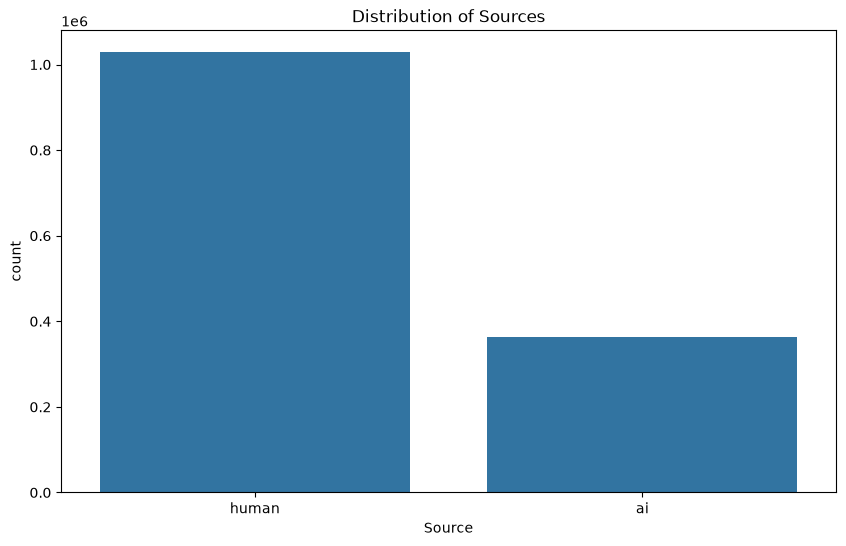

In [36]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='source', order=df['source'].value_counts().index)
plt.title('Distribution of Sources')
plt.xlabel('Source')

plt.savefig('../assets/images/source_distribution.png', dpi=300, bbox_inches='tight')

In [37]:
df.head()

,source,text
0,human,12 Years a Slave: An Analysis of the Film Essa...
1,human,20+ Social Media Post Ideas to Radically Simpl...
2,human,2022 Russian Invasion of Ukraine in Global Med...
3,human,533 U.S. 27 (2001) Kyllo v. United States: The...
4,human,A Charles Schwab Corporation Case Essay\n\nCha...


In [5]:
import pandas as pd

# 1. Standardize string text (strip spaces & convert to lowercase)
df['source_clean'] = df['source'].astype(str).str.lower().str.strip()

# 2. Define binary mapping dictionary
label_map = {
    'human': 0,
    'ai': 1,
}

# 3. Create/Overwrite target encoding column
df['target'] = df['source_clean'].map(label_map)

# Handle any unmapped sources (default to label column if present)
if df['target'].isna().any():
    df['target'] = df['target'].fillna(df['label'])

df['target'] = df['target'].astype(int)

# Verify the encoding
print(df[['source', 'source_clean', 'target']].head())
print("\nTarget Value Counts (0 = Human, 1 = AI):")
print(df['target'].value_counts())

  source source_clean  target
0  human        human       0
1  human        human       0
2  human        human       0
3  human        human       0
4  human        human       0

Target Value Counts (0 = Human, 1 = AI):
target
0    1028146
1     364376
Name: count, dtype: int64


In [6]:
df.drop(columns=['source_clean'], inplace=True)
df.drop(columns=['source'], inplace=True)

In [44]:
df.head()

,text,target
0,12 Years a Slave: An Analysis of the Film Essa...,0
1,20+ Social Media Post Ideas to Radically Simpl...,0
2,2022 Russian Invasion of Ukraine in Global Med...,0
3,533 U.S. 27 (2001) Kyllo v. United States: The...,0
4,A Charles Schwab Corporation Case Essay\n\nCha...,0


In [45]:
df['target'].value_counts()

target
0    1028146
1     364376
Name: count, dtype: int64

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Ensure text and target columns are properly formatted
df['text'] = df['text'].fillna('').astype(str)
df['target'] = df['target'].astype(int)

# Filter out empty or extremely short texts
df_clean = df[df['text'].str.len() > 20].reset_index(drop=True)

# 1. Stratified sampling (200k subset)
SAMPLE_SIZE = min(200000, len(df_clean))
df_sample = (
    df_clean.groupby('target', group_keys=False)
    .apply(lambda x: x.sample(int(SAMPLE_SIZE * len(x) / len(df_clean)), random_state=42))
    .reset_index(drop=True)
)

# 2. Train / Validation / Test Split (80% Train, 10% Val, 10% Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    df_sample['text'], 
    df_sample['target'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df_sample['target']
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, 
    y_temp, 
    test_size=0.5, 
    random_state=42, 
    stratify=y_temp
)

print(f"Train size: {len(X_train)} | Val size: {len(X_val)} | Test size: {len(X_test)}")

Train size: 159999 | Val size: 20000 | Test size: 20000


C:\Users\vinay kumar\AppData\Local\Temp\ipykernel_18000\2599453260.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(int(SAMPLE_SIZE * len(x) / len(df_clean)), random_state=42))


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from pathlib import Path
import joblib

# Store artifacts in the project models directory.
project_root = Path.cwd()
if not (project_root / "models").is_dir() and (project_root.parent / "models").is_dir():
    project_root = project_root.parent
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Feature Extraction (Unigram + Bigram TF-IDF)
print("Extracting TF-IDF features...")
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=3,
    strip_accents='unicode'
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 2. Model Training with Log-Loss (Logistic Regression behavior)
print("Training classifier...")
model = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-5, max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

# Save both fitted artifacts in models/.
vectorizer_path = models_dir / "tfidf_vectorizer.pkl"
model_path = models_dir / "detector_model.pkl"
joblib.dump(vectorizer, vectorizer_path)
joblib.dump(model, model_path)
print(f"Saved artifacts to {models_dir}")

# 3. Evaluation
y_pred = model.predict(X_test_tfidf)
y_prob = model.predict_proba(X_test_tfidf)[:, 1]

print("\n================ Classification Report ================")
print(classification_report(y_test, y_pred, target_names=["Human (0)", "AI (1)"]))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Extracting TF-IDF features...
Training classifier...
Saved artifacts to c:\Users\vinay kumar\Downloads\ai paper detection\models

================ Classification Report ================
              precision    recall  f1-score   support

   Human (0)       0.94      0.96      0.95     14774
      AI (1)       0.89      0.83      0.86      5226

    accuracy                           0.93     20000
   macro avg       0.91      0.90      0.90     20000
weighted avg       0.93      0.93      0.93     20000

ROC-AUC Score: 0.9772
Confusion Matrix:
 [[14217   557]
 [  884  4342]]


In [28]:
import joblib
from pathlib import Path

# Find the project root containing both saved model artifacts.
project_root = next(
    (
        directory
        for directory in [Path.cwd(), *Path.cwd().parents]
        if (directory / "models" / "tfidf_vectorizer.pkl").is_file()
        and (directory / "models" / "detector_model.pkl").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Saved model artifacts were not found in any project models folder.")

models_dir = project_root / "models"
vectorizer = joblib.load(models_dir / "tfidf_vectorizer.pkl")
model = joblib.load(models_dir / "detector_model.pkl")
print(f"Model and vectorizer loaded successfully from {models_dir}")

Model and vectorizer loaded successfully from c:\Users\vinay kumar\Downloads\ai paper detection\models


In [30]:
import joblib

# 1. Load Saved Model Artifacts
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")
model = joblib.load("../models/detector_model.pkl")

print("Model and vectorizer loaded successfully!")

# 2. Define Prediction Function
def predict_ai_generated(text: str, threshold: float = 0.5):
    """
    Predicts whether a given text is Human-Authored (0) or AI-Generated (1).
    Returns class label, confidence percentage, and raw probabilities.
    """
    # Preprocess and extract TF-IDF features
    features = vectorizer.transform([text])
    
    # Get class probabilities
    probabilities = model.predict_proba(features)[0]
    human_prob, ai_prob = probabilities[0], probabilities[1]
    
    # Determine final prediction based on threshold
    label = "AI-Generated" if ai_prob >= threshold else "Human-Authored"
    confidence = ai_prob if label == "AI-Generated" else human_prob
    
    return {
        "prediction": label,
        "confidence": round(confidence * 100, 2),
        "ai_probability": round(ai_prob * 100, 2),
        "human_probability": round(human_prob * 100, 2)
    }

# 3. Test on Sample Texts
sample_ai_text = """
In this paper, we present a comprehensive analysis of deep learning architectures for natural language processing tasks. 
Furthermore, our proposed model leverages transformer representations to achieve state-of-the-art performance across diverse benchmarks. 
In conclusion, the experimental results demonstrate significant improvements in classification accuracy and computational efficiency.
"""

sample_human_text = """
We present new measurements of cosmic microwave background anisotropy at 148 GHz and 218 GHz made with the Atacama Cosmology Telescope. 
Data collected during the 2008 southern season were processed using a map-making pipeline based on maximum likelihood estimation.
"""

print("=== Sample 1 Prediction (AI-Style) ===")
print(predict_ai_generated(sample_ai_text))

print("\n=== Sample 2 Prediction (Human-Style) ===")
print(predict_ai_generated(sample_human_text))

Model and vectorizer loaded successfully!
=== Sample 1 Prediction (AI-Style) ===
{'prediction': 'Human-Authored', 'confidence': np.float64(96.99), 'ai_probability': np.float64(3.01), 'human_probability': np.float64(96.99)}

=== Sample 2 Prediction (Human-Style) ===
{'prediction': 'Human-Authored', 'confidence': np.float64(52.61), 'ai_probability': np.float64(47.39), 'human_probability': np.float64(52.61)}


In [32]:
import joblib
from pathlib import Path

# 1. Dynamically locate model artifacts in root or models/ directory
base_dir = Path.cwd()
models_dir = base_dir / "models"

if (base_dir / "../models/tfidf_vectorizer.pkl").exists():
    vectorizer_path = base_dir / "../models/tfidf_vectorizer.pkl"
    model_path = base_dir / "../models/detector_model.pkl"
elif (models_dir / "tfidf_vectorizer.pkl").exists():
    vectorizer_path = models_dir / "tfidf_vectorizer.pkl"
    model_path = models_dir / "detector_model.pkl"
else:
    raise FileNotFoundError("Could not find 'tfidf_vectorizer.pkl' or 'detector_model.pkl'. Ensure training has run.")

# 2. Load model artifacts
vectorizer = joblib.load(vectorizer_path)
model = joblib.load(model_path)

# 3. Prediction Function
def predict_text(text: str, threshold: float = 0.5):
    features = vectorizer.transform([text])
    probabilities = model.predict_proba(features)[0]
    human_prob, ai_prob = probabilities[0], probabilities[1]
    
    label = "AI-Generated" if ai_prob >= threshold else "Human-Authored"
    confidence = ai_prob if label == "AI-Generated" else human_prob
    
    return {
        "text_preview": text[:80] + "..." if len(text) > 80 else text,
        "prediction": label,
        "confidence": f"{confidence * 100:.2f}%",
        "ai_probability": f"{ai_prob * 100:.2f}%",
        "human_probability": f"{human_prob * 100:.2f}%"
    }

# 4. Test Sample Sentences
test_sentences = [
    # Sample 1 (AI-generated style)
    "In conclusion, our research provides a comprehensive analysis of machine learning frameworks, highlighting significant improvements in performance.",
    
    # Sample 2 (Human-authored paper style)
    "We measured the thermal conductivity of synthesized graphene samples using a customized 3-omega experimental setup.",
    
    # Sample 3 (AI-generated essay style)
    "Furthermore, it is crucial to consider the various socio-economic implications when evaluating the overall impact of artificial intelligence on society.",
    
    # Sample 4 (Human-authored legal text style)
    "The petitioner filed a writ under Article 226 of the Constitution challenging the administrative decision on grounds of natural justice violations."
]

print("================ MODEL PREDICTIONS ================\n")
for idx, sentence in enumerate(test_sentences, 1):
    result = predict_text(sentence)
    print(f"Sample {idx}:")
    print(f"  Text: \"{result['text_preview']}\"")
    print(f"  Result: {result['prediction']} (Confidence: {result['confidence']})")
    print(f"  Raw Breakdown -> AI: {result['ai_probability']} | Human: {result['human_probability']}\n")

================ MODEL PREDICTIONS ================

Sample 1:
  Text: "In conclusion, our research provides a comprehensive analysis of machine learnin..."
  Result: Human-Authored (Confidence: 74.49%)
  Raw Breakdown -> AI: 25.51% | Human: 74.49%

Sample 2:
  Text: "We measured the thermal conductivity of synthesized graphene samples using a cus..."
  Result: Human-Authored (Confidence: 75.56%)
  Raw Breakdown -> AI: 24.44% | Human: 75.56%

Sample 3:
  Text: "Furthermore, it is crucial to consider the various socio-economic implications w..."
  Result: Human-Authored (Confidence: 67.45%)
  Raw Breakdown -> AI: 32.55% | Human: 67.45%

Sample 4:
  Text: "The petitioner filed a writ under Article 226 of the Constitution challenging th..."
  Result: Human-Authored (Confidence: 56.57%)
  Raw Breakdown -> AI: 43.43% | Human: 56.57%

